# Pertemuan 9 — Mengenali Jenis Detak Jantung dari Sinyal EKG dengan 1D CNN

**Kecerdasan Buatan (BM25-41204) · Teknik Biomedis ITERA** — Martin C.T. Manullang

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mctosima/ai-bm/blob/main/pertemuan-09/klasifikasi_ekg_1d_cnn.ipynb)

Di notebook ini kita akan mengajari komputer untuk **melihat satu detak jantung pada rekaman EKG, lalu menebak jenis detaknya**: normal, atau salah satu jenis detak tidak normal (aritmia).

**Kamu tidak perlu pernah ngoding sebelumnya.** Setiap langkah dijelaskan dengan bahasa sehari-hari.

### Yang akan kamu pelajari
1. Seperti apa data sinyal EKG ketika masuk ke komputer.
2. Apa itu *1D Convolutional Neural Network* (1D CNN) — tanpa rumus yang menakutkan.
3. Cara melatih model dengan **PyTorch**.
4. Cara menilai apakah model benar-benar bagus (dan kenapa *akurasi bisa menipu*).

## Cara memakai notebook ini

Notebook terdiri dari **sel**. Ada dua jenis sel:
- **Sel teks** (seperti yang sedang kamu baca) — berisi penjelasan.
- **Sel kode** (kotak abu-abu) — berisi perintah untuk komputer.

Untuk menjalankan sel kode: klik selnya, lalu tekan **Shift + Enter**. Jalankan **berurutan dari atas ke bawah**, jangan melompat.

Di dalam kode, tulisan yang diawali tanda pagar `#` adalah **komentar**: catatan untuk manusia, tidak dibaca oleh komputer. Bacalah komentar-komentar itu — di sanalah penjelasan setiap baris.

> **Di Google Colab?** Supaya lebih cepat, pakai GPU: menu **Runtime → Change runtime type → T4 GPU → Save**. Tanpa GPU pun tetap jalan, hanya lebih lambat.

---
## Bagian 0 — Cerita singkatnya

**Elektrokardiogram (EKG)** merekam aktivitas listrik jantung. Setiap detak jantung menghasilkan pola khas: gelombang kecil **P**, lonjakan tajam **QRS**, lalu gelombang **T**.

Seorang dokter jantung bisa melihat bentuk satu detak dan berkata, *"ini detak normal"* atau *"ini detak prematur dari ventrikel"*. Kita ingin komputer bisa melakukan hal yang sama.

Caranya bukan dengan menulis aturan satu per satu (*"kalau puncaknya lebih dari sekian, maka..."*), melainkan dengan **memberi komputer puluhan ribu contoh detak beserta jawabannya**, lalu membiarkan komputer menemukan polanya sendiri. Inilah inti dari *machine learning*.

### Dataset yang kita pakai
**ECG Heartbeat Categorization Dataset** dari Kaggle (Kachuee dkk., 2018). Data ini diambil dari **MIT-BIH Arrhythmia Database** yang sudah sangat terkenal di dunia riset jantung. Kabar baiknya, data sudah disiapkan dengan rapi:
- Setiap baris = **satu detak jantung** yang sudah dipotong.
- Setiap detak berisi **187 angka** (sampel sinyal, direkam 125 kali per detik). Detak yang lebih pendek diisi angka 0 di ujungnya.
- Kolom terakhir adalah **label** (jawaban) berupa angka 0–4:

| Label | Kode | Arti |
|---|---|---|
| 0 | **N** | Detak normal |
| 1 | **S** | Detak prematur dari serambi (*supraventricular ectopic*) |
| 2 | **V** | Detak prematur dari bilik (*ventricular ectopic*) |
| 3 | **F** | Detak gabungan normal + ventrikel (*fusion*) |
| 4 | **Q** | Tidak dapat dikelompokkan (termasuk detak alat pacu jantung) |

Tugas model kita: **diberi 187 angka sebuah detak → tebak labelnya (0, 1, 2, 3, atau 4).** Ini disebut **klasifikasi**.

---
## Bagian 1 — Menyiapkan alat

Kita tidak membuat semuanya dari nol. Kita meminjam **library** (kumpulan alat siap pakai) buatan orang lain dengan perintah `import`. Analoginya: sebelum memasak, kita mengeluarkan panci, pisau, dan kompor dari lemari.

In [1]:
import numpy as np                  # alat hitung untuk deretan angka
import pandas as pd                 # alat membaca tabel (mirip Excel)
import matplotlib.pyplot as plt     # alat menggambar grafik
import torch                        # PyTorch: alat utama deep learning
import torch.nn as nn               # nn = neural network, berisi "balok lego" untuk menyusun model
from torch.utils.data import TensorDataset, DataLoader   # alat membagi data menjadi kelompok kecil
from sklearn.metrics import ConfusionMatrixDisplay, classification_report  # alat menilai hasil

# Angka acak dibuat "tetap" supaya hasilmu sama setiap kali notebook dijalankan ulang
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch versi", torch.__version__)

PyTorch versi 2.14.1


### Memilih "mesin" untuk melatih model

Melatih model deep learning adalah pekerjaan hitung yang sangat banyak. **GPU** (kartu grafis) bisa mengerjakannya jauh lebih cepat daripada **CPU** (prosesor biasa). Kode di bawah mencoba urutan ini:
1. **CUDA** — GPU NVIDIA (misalnya di Google Colab atau PC lab).
2. **MPS** — GPU bawaan Mac dengan chip Apple (M1, M2, M3, ...).
3. **CPU** — kalau tidak ada GPU sama sekali. Tetap jalan, hanya lebih lambat.

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")      # GPU NVIDIA
elif torch.backends.mps.is_available():
    device = torch.device("mps")       # GPU Apple Silicon
else:
    device = torch.device("cpu")       # prosesor biasa

print("Model akan dilatih memakai:", device)

Model akan dilatih memakai: mps


---
## Bagian 2 — Mengunduh dataset dari Kaggle

Kita memakai library `kagglehub` untuk mengunduh dataset langsung dari Kaggle (±100 MB) ke folder `data/` di sebelah notebook ini. Cukup sekali; kalau sel ini dijalankan lagi, file yang sudah ada di `data/` akan dipakai ulang tanpa mengunduh lagi.

In [3]:
try:
    import kagglehub
except ImportError:            # kalau kagglehub belum terpasang, pasang dulu
    %pip install -q kagglehub
    import kagglehub

# output_dir="data" → simpan di folder data/ di sebelah notebook ini
folder_data = kagglehub.dataset_download("shayanfazeli/heartbeat", output_dir="data")
print("Dataset tersimpan di:", folder_data)

/Users/martinmanullang/Developer/ai-bm/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset tersimpan di: data


---
## Bagian 3 — Membaca data

Dataset sudah dibagi oleh pembuatnya menjadi dua file:
- `mitbih_train.csv` → **data latih**: dipakai model untuk belajar (seperti soal latihan).
- `mitbih_test.csv` → **data uji**: **tidak pernah dilihat** model saat belajar, dipakai untuk menilai di akhir (seperti soal ujian).

Kenapa dipisah? Kalau soal ujian sama dengan soal latihan, nilai bagus belum tentu berarti paham — bisa jadi hanya hafal.

In [4]:
# header=None karena file ini tidak punya baris judul kolom
data_latih = pd.read_csv(folder_data + "/mitbih_train.csv", header=None)
data_uji = pd.read_csv(folder_data + "/mitbih_test.csv", header=None)

print("Jumlah detak di data latih:", len(data_latih))
print("Jumlah detak di data uji  :", len(data_uji))

# Tampilkan 5 baris pertama: setiap baris adalah satu detak
data_latih.head()

Jumlah detak di data latih: 87554
Jumlah detak di data uji  : 21892


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Tabel di atas punya 188 kolom. Kolom **0 sampai 186** adalah sinyal (187 angka), kolom **187** (paling kanan) adalah label.

Sekarang kita pisahkan keduanya:
- `X` = sinyal (yang dilihat model)
- `y` = label (jawaban yang benar)

NameError: name 'nama_kelas' is not defined

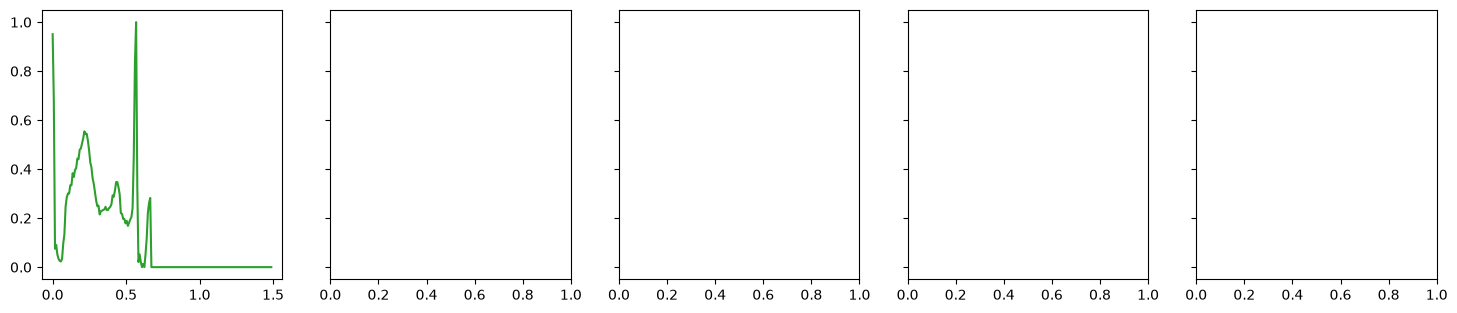

In [ ]:
# Pilih 5 detak secara acak tanpa mengambil baris yang sama
indeks_acak = np.random.choice(len(data_latih), size=5, replace=False)
waktu = np.arange(187) / 125  # frekuensi sampel 125 Hz

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)

for ax, indeks in zip(axes, indeks_acak):
    sinyal = data_latih.iloc[indeks, :187].to_numpy()
    label = int(data_latih.iloc[indeks, 187])

    ax.plot(waktu, sinyal, color="tab:green")
    ax.set_title(f"Baris {indeks}\nKelas {('N', 'S', 'V', 'F', 'Q')[label]}")
    ax.set_xlabel("Waktu (detik)")

axes[0].set_ylabel("Amplitudo")
plt.suptitle("Lima detak EKG acak dari data latih")
plt.tight_layout()
plt.show()

In [5]:
# .iloc[baris, kolom] artinya "ambil bagian tabel". Tanda : artinya "semua".
X_latih = data_latih.iloc[:, :187].values          # semua baris, kolom 0..186 → sinyal
y_latih = data_latih.iloc[:, 187].values.astype(int)  # semua baris, kolom 187 → label

X_uji = data_uji.iloc[:, :187].values
y_uji = data_uji.iloc[:, 187].values.astype(int)

print("Ukuran X_latih:", X_latih.shape, "→ (jumlah detak, panjang sinyal)")
print("Ukuran y_latih:", y_latih.shape)

# Nama setiap kelas, urut sesuai labelnya (0, 1, 2, 3, 4)
nama_kelas = ["N (normal)", "S (supraventrikular)", "V (ventrikular)", "F (fusion)", "Q (tak terklasifikasi)"]
kode_kelas = ["N", "S", "V", "F", "Q"]

Ukuran X_latih: (87554, 187) → (jumlah detak, panjang sinyal)
Ukuran y_latih: (87554,)


---
## Bagian 4 — Melihat datanya dulu

Aturan emas: **jangan pernah melatih model sebelum melihat datanya sendiri.** Mari gambar satu contoh detak dari setiap kelas.

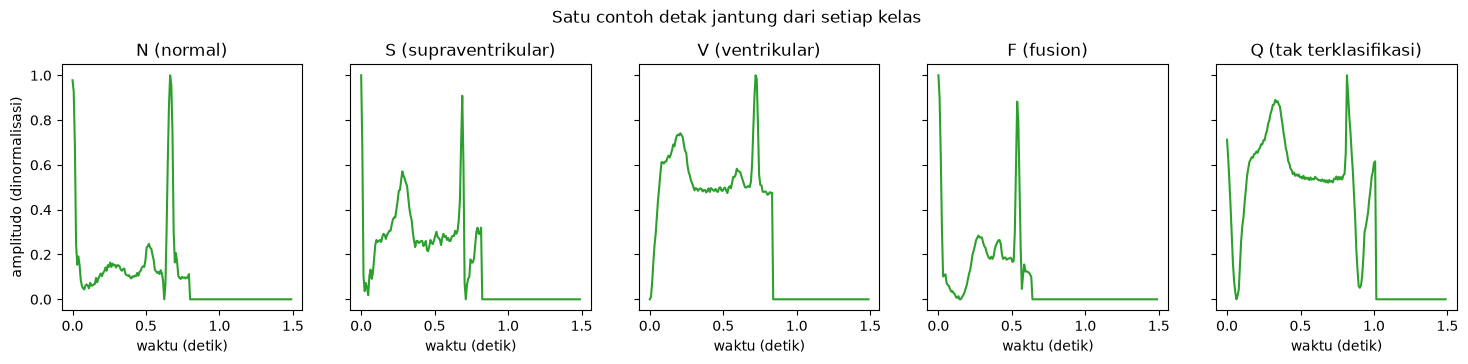

In [6]:
waktu = np.arange(187) / 125      # 125 sampel per detik → ubah nomor sampel menjadi detik

fig, axes = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
for label in range(5):
    contoh = np.where(y_latih == label)[0][0]     # ambil detak pertama yang berlabel ini
    axes[label].plot(waktu, X_latih[contoh], color="tab:green")
    axes[label].set_title(nama_kelas[label])
    axes[label].set_xlabel("waktu (detik)")
axes[0].set_ylabel("amplitudo (dinormalisasi)")
plt.suptitle("Satu contoh detak jantung dari setiap kelas", y=1.05)
plt.show()

**Cara membaca grafiknya:** setiap potongan **dimulai tepat di puncak R** (lonjakan tinggi di ujung kiri), lalu ada gelombang T, gelombang P, dan lonjakan R detak berikutnya. Setelah itu sinyal bernilai 0 — itu bukan bagian dari jantung, melainkan angka pengisi supaya semua detak sama panjang (187 angka).

Perhatikan bentuknya berbeda-beda: jarak ke detak berikutnya, lebar lonjakan, bentuk gelombang di antaranya, dan sebagainya. Bentuk-bentuk inilah yang nanti harus dikenali model.

Sekarang hitung **berapa banyak contoh untuk setiap kelas**:

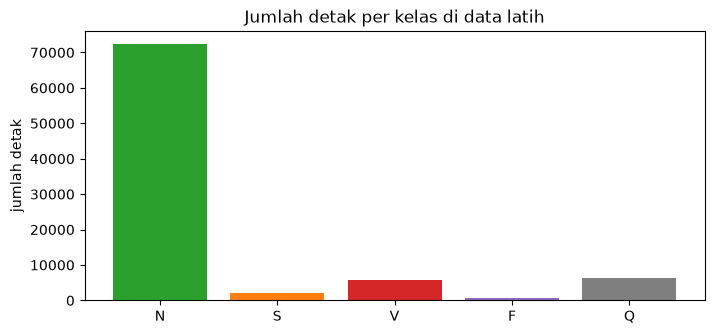

N:  72471 detak (82.8%)
S:   2223 detak (2.5%)
V:   5788 detak (6.6%)
F:    641 detak (0.7%)
Q:   6431 detak (7.3%)


In [7]:
jumlah_per_kelas = np.bincount(y_latih)    # hitung berapa kali setiap label muncul

plt.figure(figsize=(8, 3.5))
plt.bar(kode_kelas, jumlah_per_kelas, color=["tab:green", "tab:orange", "tab:red", "tab:purple", "tab:gray"])
plt.title("Jumlah detak per kelas di data latih")
plt.ylabel("jumlah detak")
plt.show()

for kode, jumlah in zip(kode_kelas, jumlah_per_kelas):
    print(f"{kode}: {jumlah:6d} detak ({jumlah / len(y_latih):.1%})")

**Penting!** Data ini **tidak seimbang**: sebagian besar detak adalah normal (N), sedangkan kelas F hanya sekitar 1%. Hal ini wajar di dunia medis — kondisi tidak normal memang lebih jarang. Tapi ini akan memengaruhi cara kita menilai model nanti. Ingat-ingat fakta ini.

---
## Bagian 5 — Mengubah data menjadi format PyTorch

PyTorch bekerja dengan **tensor** — sebut saja "tabel angka yang bisa diproses GPU".

Model 1D CNN mengharapkan data berbentuk **(jumlah detak, jumlah kanal, panjang sinyal)**. Kita hanya punya **1 kanal** (satu sadapan/*lead* EKG), jadi bentuknya menjadi `(jumlah detak, 1, 187)`. Kalau kita punya EKG 12 sadapan, jumlah kanalnya 12.

In [8]:
# float32 = angka desimal, long = bilangan bulat (label harus bilangan bulat)
# unsqueeze(1) menyisipkan dimensi "kanal": (N, 187) → (N, 1, 187)
X_latih_t = torch.tensor(X_latih, dtype=torch.float32).unsqueeze(1)
y_latih_t = torch.tensor(y_latih, dtype=torch.long)
X_uji_t = torch.tensor(X_uji, dtype=torch.float32).unsqueeze(1)
y_uji_t = torch.tensor(y_uji, dtype=torch.long)

print("Bentuk data latih:", tuple(X_latih_t.shape))

Bentuk data latih: (87554, 1, 187)


Model tidak belajar dari 87 ribu detak sekaligus, melainkan **sedikit demi sedikit** dalam kelompok kecil yang disebut **batch** (di sini 128 detak per batch). `DataLoader` adalah "petugas" yang menyiapkan batch-batch itu. Untuk data latih, urutannya diacak (`shuffle=True`) supaya model tidak menghafal urutan.

In [9]:
UKURAN_BATCH = 128

loader_latih = DataLoader(TensorDataset(X_latih_t, y_latih_t), batch_size=UKURAN_BATCH, shuffle=True)
loader_uji = DataLoader(TensorDataset(X_uji_t, y_uji_t), batch_size=UKURAN_BATCH, shuffle=False)

print("Jumlah batch latih per putaran:", len(loader_latih))

Jumlah batch latih per putaran: 685


---
## Bagian 6 — Membangun model 1D CNN

### Apa itu konvolusi 1D?
Bayangkan kamu punya **kaca pembesar kecil** selebar 5 titik sinyal. Kaca pembesar itu kamu **geser pelan-pelan** dari ujung kiri sampai ujung kanan sinyal. Di setiap posisi, kaca pembesar bertanya: *"apakah bagian sinyal di sini mirip dengan pola yang aku cari?"* — misalnya pola lonjakan tajam, atau pola menurun landai.

Satu kaca pembesar = satu **filter** = satu detektor pola. Lapisan konvolusi punya banyak filter sekaligus, dan **model sendiri yang belajar pola apa yang perlu dicari**. Kita tidak perlu menentukannya.

### Susunan model kita
```
sinyal (1 × 187)
  → Konvolusi: 16 filter    → ReLU → MaxPool   (cari pola sederhana, lalu ringkas → 16 × 93)
  → Konvolusi: 32 filter    → ReLU → MaxPool   (gabungkan jadi pola lebih rumit   → 32 × 46)
  → Konvolusi: 64 filter    → ReLU → MaxPool   (gabungkan lagi jadi pola kompleks → 64 × 23)
  → Flatten                                      (jejerkan jadi satu baris: 1472 angka)
  → Linear 64 → ReLU → Linear 5                  (ambil keputusan → 5 skor, satu per kelas)
```
- **ReLU**: buang nilai negatif, hanya simpan pola yang "menyala".
- **MaxPool**: ringkas sinyal jadi setengah panjangnya dengan mengambil nilai terbesar di setiap pasangan — seperti membuat ringkasan.
- **Linear**: lapisan "pengambil keputusan" yang menggabungkan semua pola yang ditemukan.

Kelas dengan **skor tertinggi** menjadi tebakan model.

In [10]:
model = nn.Sequential(
    # Blok 1: 16 filter, masing-masing selebar 5 titik. padding=2 menjaga panjang sinyal tetap 187.
    nn.Conv1d(in_channels=1, out_channels=16, kernel_size=5, padding=2),
    nn.ReLU(),
    nn.MaxPool1d(2),                     # 187 → 93

    # Blok 2: 32 filter yang membaca hasil 16 filter sebelumnya
    nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, padding=2),
    nn.ReLU(),
    nn.MaxPool1d(2),                     # 93 → 46

    # Blok 3: 64 filter yang membaca hasil 32 filter sebelumnya
    nn.Conv1d(in_channels=32, out_channels=64, kernel_size=5, padding=2),
    nn.ReLU(),
    nn.MaxPool1d(2),                     # 46 → 23

    # Bagian pengambil keputusan
    nn.Flatten(),                        # 64 × 23 = 1472 angka dalam satu baris
    nn.Linear(64 * 23, 64),
    nn.ReLU(),
    nn.Linear(64, 5),                    # 5 skor keluaran = 5 kelas
)
model = model.to(device)                 # pindahkan model ke GPU/CPU yang dipilih tadi

jumlah_parameter = sum(p.numel() for p in model.parameters())
print(model)
print(f"Jumlah parameter (angka yang akan dipelajari model): {jumlah_parameter:,}")

Sequential(
  (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
  (1): ReLU()
  (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (4): ReLU()
  (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1472, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=5, bias=True)
)
Jumlah parameter (angka yang akan dipelajari model): 97,285


Sebelum melatih, mari **coba masukkan satu detak** ke model. Karena model belum belajar apa-apa, tebakannya masih asal.

In [11]:
satu_detak = X_latih_t[:1].to(device)     # ambil detak pertama, bentuk (1, 1, 187)
skor = model(satu_detak)
print("Skor untuk 5 kelas:", skor.detach().cpu().numpy().round(3))
print("Tebakan model (belum dilatih):", nama_kelas[skor.argmax().item()])
print("Jawaban sebenarnya            :", nama_kelas[y_latih[0]])

Skor untuk 5 kelas: [[ 0.01   0.099  0.008  0.1   -0.002]]
Tebakan model (belum dilatih): F (fusion)
Jawaban sebenarnya            : N (normal)


---
## Bagian 7 — Melatih model

Untuk belajar, model butuh dua hal:
1. **Fungsi loss** (`CrossEntropyLoss`): mengukur **seberapa salah** tebakan model. Makin kecil, makin baik.
2. **Optimizer** (`Adam`): cara **memperbaiki** model sedikit demi sedikit agar loss mengecil. `lr` (*learning rate*) menentukan seberapa besar langkah perbaikannya.

Lalu kita ulangi **resep 5 langkah** ini untuk setiap batch:

| Langkah | Kode | Artinya |
|---|---|---|
| 1 | `keluaran = model(sinyal)` | Model menebak |
| 2 | `loss = fungsi_loss(keluaran, label)` | Hitung seberapa salah |
| 3 | `optimizer.zero_grad()` | Bersihkan catatan koreksi sebelumnya |
| 4 | `loss.backward()` | Cari arah perbaikan (*backpropagation*) |
| 5 | `optimizer.step()` | Perbaiki model sedikit |

Satu kali melewati **seluruh** data latih disebut satu **epoch**. Kita akan melakukan 10 epoch.

In [12]:
fungsi_loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

JUMLAH_EPOCH = 10
riwayat_loss = []
riwayat_akurasi = []

for epoch in range(JUMLAH_EPOCH):
    model.train()                       # mode belajar
    total_loss, jumlah_benar, jumlah_data = 0.0, 0, 0

    for sinyal, label in loader_latih:
        sinyal, label = sinyal.to(device), label.to(device)

        keluaran = model(sinyal)                 # 1. tebak
        loss = fungsi_loss(keluaran, label)      # 2. hitung seberapa salah
        optimizer.zero_grad()                    # 3. bersihkan koreksi lama
        loss.backward()                          # 4. cari arah perbaikan
        optimizer.step()                         # 5. perbaiki model

        # catat hasil untuk laporan
        total_loss += loss.item() * len(label)
        jumlah_benar += (keluaran.argmax(dim=1) == label).sum().item()
        jumlah_data += len(label)

    riwayat_loss.append(total_loss / jumlah_data)
    riwayat_akurasi.append(jumlah_benar / jumlah_data)
    print(f"Epoch {epoch + 1:2d}/{JUMLAH_EPOCH} | loss = {riwayat_loss[-1]:.4f} | akurasi latih = {riwayat_akurasi[-1]:.2%}")

Epoch  1/10 | loss = 0.3115 | akurasi latih = 91.29%


Epoch  2/10 | loss = 0.1587 | akurasi latih = 95.71%


Epoch  3/10 | loss = 0.1290 | akurasi latih = 96.45%


Epoch  4/10 | loss = 0.1114 | akurasi latih = 96.96%


Epoch  5/10 | loss = 0.0998 | akurasi latih = 97.21%


Epoch  6/10 | loss = 0.0910 | akurasi latih = 97.43%


Epoch  7/10 | loss = 0.0833 | akurasi latih = 97.67%


Epoch  8/10 | loss = 0.0790 | akurasi latih = 97.73%


Epoch  9/10 | loss = 0.0740 | akurasi latih = 97.88%


Epoch 10/10 | loss = 0.0699 | akurasi latih = 98.01%


Mari lihat perkembangan belajarnya dalam grafik. Yang kita harapkan: **loss turun** dan **akurasi naik** dari epoch ke epoch.

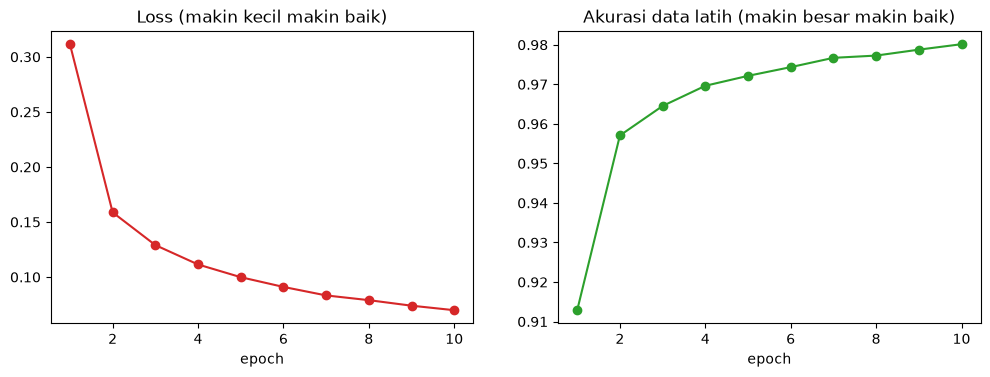

In [13]:
epoch_ke = range(1, JUMLAH_EPOCH + 1)
fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(12, 3.8))

kiri.plot(epoch_ke, riwayat_loss, marker="o", color="tab:red")
kiri.set_title("Loss (makin kecil makin baik)")
kiri.set_xlabel("epoch")

kanan.plot(epoch_ke, riwayat_akurasi, marker="o", color="tab:green")
kanan.set_title("Akurasi data latih (makin besar makin baik)")
kanan.set_xlabel("epoch")
plt.show()

---
## Bagian 8 — Ujian: menilai model dengan data uji

Sekarang saatnya ujian. Model diminta menebak **21 ribu detak yang belum pernah dilihatnya**.

- `model.eval()` → mode ujian (bukan belajar).
- `torch.no_grad()` → "tidak perlu mencatat koreksi", karena kita tidak sedang belajar. Ini membuat proses lebih cepat dan hemat memori.

In [14]:
model.eval()
semua_tebakan = []

with torch.no_grad():
    for sinyal, label in loader_uji:
        keluaran = model(sinyal.to(device))
        semua_tebakan.append(keluaran.argmax(dim=1).cpu())   # kelas dengan skor tertinggi

y_tebak = torch.cat(semua_tebakan).numpy()

akurasi_uji = (y_tebak == y_uji).mean()
print(f"Akurasi pada data uji: {akurasi_uji:.2%}")

Akurasi pada data uji: 97.77%


### Hati-hati: akurasi bisa menipu!

Ingat data kita tidak seimbang. Bayangkan ada "model malas" yang **selalu menjawab normal** untuk setiap detak, tanpa melihat sinyalnya sama sekali. Berapa akurasinya?

In [15]:
akurasi_model_malas = (y_uji == 0).mean()
print(f"Akurasi 'model malas' yang selalu menjawab N: {akurasi_model_malas:.2%}")
print(f"Akurasi model 1D CNN kita                  : {akurasi_uji:.2%}")

Akurasi 'model malas' yang selalu menjawab N: 82.76%
Akurasi model 1D CNN kita                  : 97.77%


Model malas saja sudah mendapat akurasi tinggi, padahal ia **tidak pernah mendeteksi satu pun detak abnormal** — tidak berguna sama sekali untuk pasien. Jadi kita butuh cara menilai yang lebih jujur.

### Confusion matrix
Tabel ini menunjukkan, untuk setiap kelas yang **sebenarnya** (baris), model menebak apa (kolom). Angka di **diagonal** adalah tebakan yang benar; angka di luar diagonal adalah kesalahan.

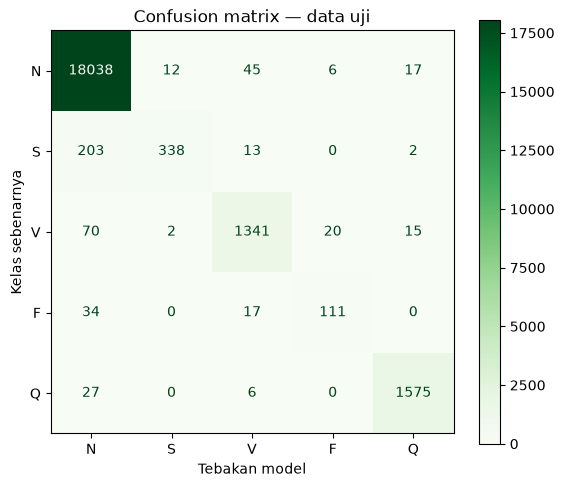

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_uji, y_tebak,
    display_labels=kode_kelas,
    cmap="Greens",
    values_format="d",
    ax=ax,
)
ax.set_xlabel("Tebakan model")
ax.set_ylabel("Kelas sebenarnya")
ax.set_title("Confusion matrix — data uji")
plt.show()

### Nilai per kelas

Laporan di bawah memberi nilai **untuk setiap kelas**:
- **recall** (di dunia medis disebut **sensitivitas**): dari semua detak kelas ini, berapa persen yang berhasil ditemukan model? *Ini yang paling penting untuk kelas abnormal — kita tidak mau melewatkan pasien yang sakit.*
- **precision**: dari semua tebakan "kelas ini", berapa persen yang memang benar?
- **f1-score**: gabungan precision dan recall dalam satu angka.

In [17]:
print(classification_report(y_uji, y_tebak, target_names=nama_kelas, digits=3))

                        precision    recall  f1-score   support

            N (normal)      0.982     0.996     0.989     18118
  S (supraventrikular)      0.960     0.608     0.744       556
       V (ventrikular)      0.943     0.926     0.934      1448
            F (fusion)      0.810     0.685     0.742       162
Q (tak terklasifikasi)      0.979     0.979     0.979      1608

              accuracy                          0.978     21892
             macro avg      0.935     0.839     0.878     21892
          weighted avg      0.977     0.978     0.976     21892



Perhatikan kelas mana yang recall-nya paling rendah. Biasanya kelas yang **contohnya paling sedikit** (S dan F) — model kurang banyak berlatih mengenali mereka. Ini salah satu tantangan nyata AI medis, dan bisa menjadi bahan **mini project** kamu.

---
## Bagian 9 — Mencoba menebak satu detak

Mari lihat model bekerja pada satu detak dari data uji. Model mengeluarkan 5 skor; dengan fungsi **softmax**, skor itu diubah menjadi **peluang** (persen) yang jumlahnya 100%.

Coba ganti `KELAS_YANG_DICARI` dengan angka 0–4 dan `URUTAN` dengan angka lain, lalu jalankan ulang selnya.

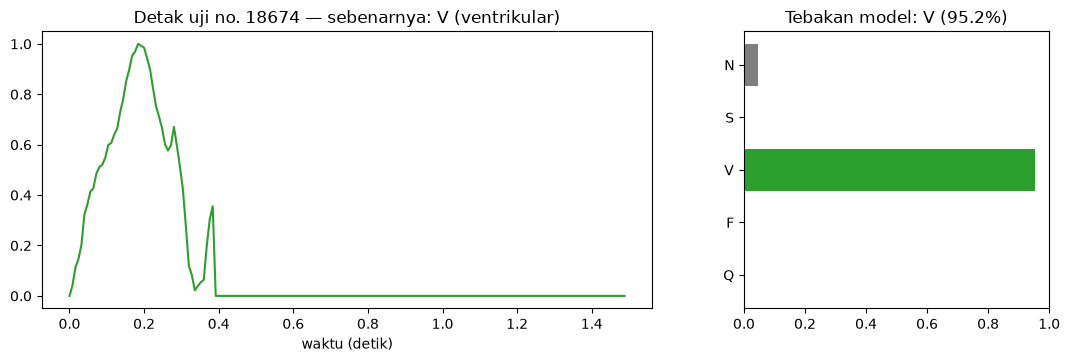

In [18]:
KELAS_YANG_DICARI = 2     # 0=N, 1=S, 2=V, 3=F, 4=Q
URUTAN = 0                # contoh ke berapa dari kelas itu

i = np.where(y_uji == KELAS_YANG_DICARI)[0][URUTAN]

with torch.no_grad():
    skor = model(X_uji_t[i:i + 1].to(device))
    peluang = torch.softmax(skor, dim=1)[0].cpu().numpy()

fig, (kiri, kanan) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1]})
kiri.plot(waktu, X_uji[i], color="tab:green")
kiri.set_title(f"Detak uji no. {i} — sebenarnya: {nama_kelas[y_uji[i]]}")
kiri.set_xlabel("waktu (detik)")

kanan.barh(kode_kelas, peluang, color="tab:gray")
kanan.barh(kode_kelas[peluang.argmax()], peluang.max(), color="tab:green")
kanan.set_xlim(0, 1)
kanan.set_title(f"Tebakan model: {kode_kelas[peluang.argmax()]} ({peluang.max():.1%})")
kanan.invert_yaxis()
plt.show()

---
## Bagian 10 — Menyimpan model

Model yang sudah dilatih bisa disimpan ke file, supaya nanti tidak perlu dilatih ulang.

In [19]:
torch.save(model.state_dict(), "model_ekg_1d_cnn.pt")
print("Model tersimpan sebagai model_ekg_1d_cnn.pt")

Model tersimpan sebagai model_ekg_1d_cnn.pt


---
## Rangkuman

| Langkah | Yang kita lakukan |
|---|---|
| Data | 87 ribu detak EKG (187 sampel) dengan 5 label dari MIT-BIH |
| Lihat data | Bentuk detak tiap kelas berbeda; data sangat tidak seimbang |
| Model | 1D CNN: 3 blok konvolusi untuk mencari pola + 2 lapisan linear untuk memutuskan |
| Latih | Resep 5 langkah diulang selama 10 epoch |
| Nilai | Akurasi saja menipu → lihat confusion matrix dan recall per kelas |

## Latihan & ide mini project

1. **Ubah jumlah epoch** (`JUMLAH_EPOCH`) menjadi 5 atau 20. Apa yang terjadi pada loss dan akurasi uji?
2. **Ubah model**: ganti jumlah filter (16 → 32, 32 → 64, 64 → 128) atau tambahkan blok konvolusi keempat. Jangan lupa: angka pada `nn.Linear(64 * 23, 64)` harus menyesuaikan panjang sinyal setelah pooling.
3. **Atasi data tidak seimbang**: beri bobot lebih besar pada kelas yang jarang, misalnya
   ```python
   bobot = torch.tensor(len(y_latih) / (5 * np.bincount(y_latih)), dtype=torch.float32).to(device)
   fungsi_loss = nn.CrossEntropyLoss(weight=bobot)
   ```
   Bandingkan recall kelas S dan F sebelum dan sesudahnya.
4. **Dataset lain di folder yang sama**: `ptbdb_normal.csv` dan `ptbdb_abnormal.csv` (PTB Diagnostic Database). Buat klasifikasi **2 kelas**: normal vs infark miokard.

## Referensi
- Kachuee, M., Fazeli, S., & Sarrafzadeh, M. (2018). *ECG Heartbeat Classification: A Deep Transferable Representation.* IEEE ICHI. https://arxiv.org/abs/1805.00794
- Dataset: https://www.kaggle.com/datasets/shayanfazeli/heartbeat